In [1]:
import uproot
import awkward as ak
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import mplhep as hep

In [2]:
file = uproot.open("C:/Users/HP/Documents/Practica Profesional/Analisis BosonHiggs/Data Sets/Run2012B_DoubleMuParked.root")
tree = file['Events']

# Listar ramas (variables físicas)

print(tree.keys())
tree.keys()
print (['nMuon', 'Muon_pt', 'Muon_eta', 'Muon_phi', 'Muon_mass', 'Muon_charge','Muon_pfRelIso04_all', 'Muon_dxy', 'Muon_dz', 'Muon_dxyErr', 'Muon_dzErr'])

['run', 'luminosityBlock', 'event', 'PV_npvs', 'PV_x', 'PV_y', 'PV_z', 'nMuon', 'Muon_pt', 'Muon_eta', 'Muon_phi', 'Muon_mass', 'Muon_charge', 'Muon_pfRelIso03_all', 'Muon_pfRelIso04_all', 'Muon_dxy', 'Muon_dxyErr', 'Muon_dz', 'Muon_dzErr', 'nElectron', 'Electron_pt', 'Electron_eta', 'Electron_phi', 'Electron_mass', 'Electron_charge', 'Electron_pfRelIso03_all', 'Electron_dxy', 'Electron_dxyErr', 'Electron_dz', 'Electron_dzErr', 'MET_pt', 'MET_phi']
['nMuon', 'Muon_pt', 'Muon_eta', 'Muon_phi', 'Muon_mass', 'Muon_charge', 'Muon_pfRelIso04_all', 'Muon_dxy', 'Muon_dz', 'Muon_dxyErr', 'Muon_dzErr']


In [3]:
# Extraer variables físicas de los tres archivos a dataframes 
# Datos reales (Run2012B)
df = tree.arrays(['Muon_pt', 'Muon_eta', 'Muon_phi', 'Muon_charge','Muon_pfRelIso04_all', 'Muon_dxy', 'Muon_dz', 'Muon_dxyErr', 'Muon_dzErr'], library="ak")


In [4]:
print("Entradas totales en el archivo de datos:", tree.num_entries)

Entradas totales en el archivo de datos: 26084708


In [5]:
# Dividimos las listas en columnas individuales para 4 muones

mask = ak.num(df["Muon_pt"]) >= 4
filtered = df[mask]  # Nuestro awkward array filtrado

# Creamos el DataFrame de Pandas extrayendo los valores directamente 
df_4mu = pd.DataFrame({ # Muón 1
        "pt1": ak.to_numpy(filtered["Muon_pt"][:, 0]),
        "eta1": ak.to_numpy(filtered["Muon_eta"][:, 0]),
        "phi1": ak.to_numpy(filtered["Muon_phi"][:, 0]),
        "charge1": ak.to_numpy(filtered["Muon_charge"][:, 0]),
        "iso1": ak.to_numpy(filtered["Muon_pfRelIso04_all"][:, 0]),
        "dxy1": ak.to_numpy(filtered["Muon_dxy"][:, 0]),
        "dz1": ak.to_numpy(filtered["Muon_dz"][:, 0]),
        "dxyErr1": ak.to_numpy(filtered["Muon_dxyErr"][:, 0]),
        "dzErr1": ak.to_numpy(filtered["Muon_dzErr"][:, 0]),
        # Muón 2
        "pt2": ak.to_numpy(filtered["Muon_pt"][:, 1]),
        "eta2": ak.to_numpy(filtered["Muon_eta"][:, 1]),
        "phi2": ak.to_numpy(filtered["Muon_phi"][:, 1]),
        "charge2": ak.to_numpy(filtered["Muon_charge"][:, 1]),
        "iso2": ak.to_numpy(filtered["Muon_pfRelIso04_all"][:, 1]),
        "dxy2": ak.to_numpy(filtered["Muon_dxy"][:, 1]),
        "dz2": ak.to_numpy(filtered["Muon_dz"][:, 1]),
        "dxyErr2": ak.to_numpy(filtered["Muon_dxyErr"][:, 1]),
        "dzErr2": ak.to_numpy(filtered["Muon_dzErr"][:, 1]),
        # Muón 3
        "pt3": ak.to_numpy(filtered["Muon_pt"][:, 2]),
        "eta3": ak.to_numpy(filtered["Muon_eta"][:, 2]),
        "phi3": ak.to_numpy(filtered["Muon_phi"][:, 2]),
        "charge3": ak.to_numpy(filtered["Muon_charge"][:, 2]),
        "iso3": ak.to_numpy(filtered["Muon_pfRelIso04_all"][:, 2]),
        "dxy3": ak.to_numpy(filtered["Muon_dxy"][:, 2]),
        "dz3": ak.to_numpy(filtered["Muon_dz"][:, 2]),
        "dxyErr3": ak.to_numpy(filtered["Muon_dxyErr"][:, 2]),
        "dzErr3": ak.to_numpy(filtered["Muon_dzErr"][:, 2]),
        # Muón 4
        "pt4": ak.to_numpy(filtered["Muon_pt"][:, 3]),
        "eta4": ak.to_numpy(filtered["Muon_eta"][:, 3]),
        "phi4": ak.to_numpy(filtered["Muon_phi"][:, 3]),
        "charge4": ak.to_numpy(filtered["Muon_charge"][:, 3]),
        "iso4": ak.to_numpy(filtered["Muon_pfRelIso04_all"][:, 3]),
        "dxy4": ak.to_numpy(filtered["Muon_dxy"][:, 3]),
        "dz4": ak.to_numpy(filtered["Muon_dz"][:, 3]),
        "dxyErr4": ak.to_numpy(filtered["Muon_dxyErr"][:, 3]),
        "dzErr4": ak.to_numpy(filtered["Muon_dzErr"][:, 3]), }
)
print("Eventos con 4 muones extraídos:", len(df_4mu))



Eventos con 4 muones extraídos: 3340080


In [6]:
# Mostrar las nuevas columnas
print(df_4mu[["pt1","pt2","pt3","pt4","eta1","eta2","eta3","eta4","phi1","phi2","phi3","phi4","charge1","charge2","charge3","charge4","iso1","iso2","iso3","iso4","dxyErr1","dzErr1"]].head())

         pt1        pt2        pt3       pt4      eta1      eta2      eta3  \
0   7.375711   7.880538   8.608316  8.115600  1.241557  1.170679 -0.536403   
1  13.697009   9.624430  11.871896  9.884266 -0.114287 -0.261180  0.097859   
2  13.364430  48.732265   3.454617  3.519238  0.938585  0.928318  0.633687   
3  23.922316   7.937217   5.440603  5.945493 -1.239026  1.650931  1.641707   
4  22.147915   4.572840   6.188020  3.954496 -0.925457 -0.365892 -0.398481   

       eta4      phi1      phi2  ...  charge1  charge2  charge3  charge4  \
0  1.253896 -2.229106  3.054800  ...        1        1       -1        1   
1 -0.263532  2.346851  2.489782  ...        1       -1       -1        1   
2  0.652571 -2.174737 -2.173148  ...       -1        1       -1        1   
3  1.718757 -1.605496  0.954863  ...        1       -1       -1       -1   
4 -0.315460  2.162648 -0.767803  ...        1        1       -1        1   

       iso1       iso2        iso3   iso4   dxyErr1    dzErr1  
0  1.89269

In [7]:
# Valores únicos de las cargas (Para confirmar que hay muones + y -)

print("Valores únicos en charge1:", df_4mu["charge1"].unique())
print("Valores únicos en charge2:", df_4mu["charge2"].unique())
print("Valores únicos en charge3:", df_4mu["charge3"].unique())
print("Valores únicos en charge4:", df_4mu["charge4"].unique())

# Imprimir el total de eventos de 4 muones listos para el análisis

print("Eventos totales con 4 muones listos para procesar:", len(df_4mu))

Valores únicos en charge1: [ 1 -1]
Valores únicos en charge2: [ 1 -1]
Valores únicos en charge3: [-1  1]
Valores únicos en charge4: [ 1 -1]
Eventos totales con 4 muones listos para procesar: 3340080


In [8]:
# Filtrar pares de muones con cargas opuestas 

df_pairs = df_4mu[(df_4mu["charge1"] + df_4mu["charge2"] + df_4mu["charge3"] + df_4mu["charge4"]) == 0].copy()

# Imprimes los resultados

print("Eventos reales de 4 muones analizados:", len(df_4mu))

Eventos reales de 4 muones analizados: 3340080


In [9]:
# Verificación de eventos totales con cuatro muones
print("Eventos con cuatro muones:", len(df_4mu))

Eventos con cuatro muones: 3340080


In [10]:
# Tabla de Flujo de Cortes para 4 muones (Datos Reales)

# Calcular sip3d solo para los 4 muones
for i in range(1, 5):
    ip3d = np.sqrt(df_4mu[f"dxy{i}"] ** 2 + df_4mu[f"dz{i}"] ** 2)
    sig = np.sqrt(df_4mu[f"dxyErr{i}"] ** 2 + df_4mu[f"dzErr{i}"] ** 2)
    df_4mu[f"sip3d{i}"] = ip3d / sig

# Definición de máscaras para 4 muones
mask_pt = (df_4mu["pt1"] > 5) & (df_4mu["pt2"] > 5) & (df_4mu["pt3"] > 5) & (df_4mu["pt4"] > 5)
mask_eta = (df_4mu["eta1"].abs() < 2.4) & (df_4mu["eta2"].abs() < 2.4) & (df_4mu["eta3"].abs() < 2.4) & (df_4mu["eta4"].abs() < 2.4)
mask_iso = (df_4mu["iso1"] < 0.40) & (df_4mu["iso2"] < 0.40) & (df_4mu["iso3"] < 0.40) & (df_4mu["iso4"] < 0.40)
mask_sip = (df_4mu["sip3d1"] < 4) & (df_4mu["sip3d2"] < 4) & (df_4mu["sip3d3"] < 4) & (df_4mu["sip3d4"] < 4)

# DataFrame final usando hasta el filtro sip3d
df_final = df_4mu[mask_pt & mask_eta & mask_iso & mask_sip].copy()

n_total = len(df_4mu)
n_pt = len(df_4mu[mask_pt])
n_eta = len(df_4mu[mask_pt & mask_eta])
n_iso = len(df_4mu[mask_pt & mask_eta & mask_iso])
n_sip = len(df_4mu[mask_pt & mask_eta & mask_iso & mask_sip])

data_flujo = {
    "Corte aplicado": [
        "Sin filtros (4 muones)",
        "pT Líderes (>5, 5 GeV)",
        "Aceptancia Detector (|eta| < 2.4)",
        "Aislamiento iso < 0.40",
        "Parámetro impacto sip3d < 4 (Final)",
    ],
    "Eventos Restantes": [n_total, n_pt, n_eta, n_iso, n_sip],
    "Aceptancia (%)": [
        100.0,
        (n_pt / n_total) * 100,
        (n_eta / n_total) * 100,
        (n_iso / n_total) * 100,
        (n_sip / n_total) * 100,
    ],
}

tabla_flujo = pd.DataFrame(data_flujo)
print("\nTabla de Flujo de Cortes (Canal H -> ZZ* -> 4mu - Datos Reales)")
print(tabla_flujo)


Tabla de Flujo de Cortes (Canal H -> ZZ* -> 4mu - Datos Reales)
                        Corte aplicado  Eventos Restantes  Aceptancia (%)
0               Sin filtros (4 muones)            3340080      100.000000
1               pT Líderes (>5, 5 GeV)            1144548       34.267083
2    Aceptancia Detector (|eta| < 2.4)            1113866       33.348483
3               Aislamiento iso < 0.40              84676        2.535149
4  Parámetro impacto sip3d < 4 (Final)              58922        1.764089


                mZ1           mZ2
count  20220.000000  20220.000000
mean      51.711760     23.903746
std       35.977322    114.077932
min        0.237479      0.000000
25%       20.403119      1.137514
50%       49.483458      5.142854
75%       85.300896     22.591012
max      333.830170   9976.856445


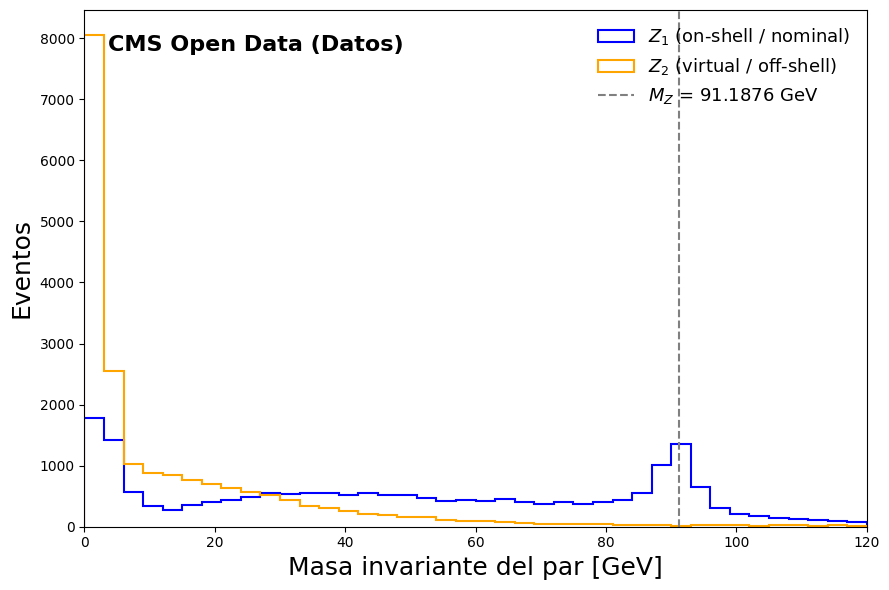

In [11]:
#  Constantes físicas 

M_Muon = 0.105658375
Z_Mass_Nominal = 91.1876


# Función para masa de un par

def masa_par(df, i, j):
  px = df[f"pt{i}"] * np.cos(df[f"phi{i}"]) + df[f"pt{j}"] * np.cos(
      df[f"phi{j}"]
  )
  py = df[f"pt{i}"] * np.sin(df[f"phi{i}"]) + df[f"pt{j}"] * np.sin(
      df[f"phi{j}"]
  )
  pz = df[f"pt{i}"] * np.sinh(df[f"eta{i}"]) + df[f"pt{j}"] * np.sinh(
      df[f"eta{j}"]
  )
  E = np.sqrt(
      df[f"pt{i}"] ** 2 + df[f"pt{i}"] ** 2 * np.sinh(df[f"eta{i}"]) ** 2 + M_Muon**2
  ) + np.sqrt(
      df[f"pt{j}"] ** 2 + df[f"pt{j}"] ** 2 * np.sinh(df[f"eta{j}"]) ** 2 + M_Muon**2
  )
  return np.sqrt(np.maximum(0.0, E**2 - (px**2 + py**2 + pz**2)))


# Identificación directa de Z1 y Z2
def identificar_Z_onoff(df):
  
  # Las 3 combinaciones posibles de pares con 4 muones
  
  pares = [((1, 2), (3, 4)), ((1, 3), (2, 4)), ((1, 4), (2, 3))]

  mejor_mZ1, mejor_mZ2, mejor_diff = (
      np.full(len(df), np.nan),
      np.full(len(df), np.nan),
      np.full(len(df), np.inf),
  )

  for (a, b), (c, d) in pares:
    valido = (df[f"charge{a}"] + df[f"charge{b}"] == 0) & (
        df[f"charge{c}"] + df[f"charge{d}"] == 0
    )
    m_ab, m_cd = masa_par(df, a, b), masa_par(df, c, d)

    ab_es_z1 = np.abs(m_ab - Z_Mass_Nominal) < np.abs(m_cd - Z_Mass_Nominal)
    m1, m2 = np.where(ab_es_z1, m_ab, m_cd), np.where(ab_es_z1, m_cd, m_ab)
    diff = np.abs(m1 - Z_Mass_Nominal)

    mask = valido & (diff < mejor_diff)
    mejor_mZ1, mejor_mZ2, mejor_diff = (
        np.where(mask, m1, mejor_mZ1),
        np.where(mask, m2, mejor_mZ2),
        np.where(mask, diff, mejor_diff),
    )

  df["mZ1"], df["mZ2"] = mejor_mZ1, mejor_mZ2
  return df


# Aplicar sobre los datos filtrados
df_final = identificar_Z_onoff(df_final)

print(df_final[["mZ1", "mZ2"]].describe())

#  Gráfica
fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    df_final["mZ1"],
    bins=40,
    range=(0, 120),
    histtype="step",
    color="blue",
    linewidth=1.5,
    label="$Z_1$ (on-shell / nominal)",
)
ax.hist(
    df_final["mZ2"],
    bins=40,
    range=(0, 120),
    histtype="step",
    color="orange",
    linewidth=1.5,
    label="$Z_2$ (virtual / off-shell)",
)
ax.axvline(
    Z_Mass_Nominal,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label=f"$M_Z$ = {Z_Mass_Nominal} GeV",
)

ax.set_xlabel("Masa invariante del par [GeV]", fontsize=18)
ax.set_ylabel("Eventos", fontsize=18)
ax.set_xlim(0, 120)

ax.text(
    0.03,
    0.92,
    "CMS Open Data (Datos)",
    transform=ax.transAxes,
    fontsize=16,
    fontweight="bold",
)
ax.legend(loc="upper right", frameon=False, fontsize=13)
plt.tight_layout()
plt.show()

In [16]:
# Verificación para dos munes 
phi1_a = 30
phi2_b = phi1_a + 180
eta_f = 0.5

df_test = pd.DataFrame({
    "pt1": df_final["pt1"], 
    "pt2": df_final["pt2"],
    "phi1": np.deg2rad(phi1_a),
    "phi2": np.deg2rad(phi2_b),
    "eta1": eta_f,
    "eta2": eta_f, })

df_test["m12"] = masa_par(df_test, 1, 2)

pt_minimo = df_test.loc[df_test["m12"].idxmin(), "pt1"]
print(f"Masa mínima: {df_test['m12'].min():.3f} GeV")
print(f"pt c: {pt_minimo:.3f} GeV")

Masa mínima: 10.091 GeV
pt c: 5.002 GeV
